# Theorie vs. Messung: Galaxy-Galaxy Lensing

- Messung: `ggl_measurements.npz` (aus `G2LShearProfile.ipynb`; Randoms subtrahiert, m-kalibriert, Boost-korrigiert, Fehler aus OneCovariance)
- Theorie: `../theory_results.npz` (aus `G2LTheory.ipynb`)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

meas = np.load('/home/rhoffmann/MA/Modelling/Compare/ggl_measurements.npz')
theo = np.load('/home/rhoffmann/MA/Modelling/theory_results.npz')

theta_theory = theo['theta']

# Kombinationen aus den Messschluesseln: '<Lens>_S<k>'
pairs = []
for key in meas.files:
    if key.startswith('gammat_'):
        lens, sb = key[len('gammat_'):].rsplit('_S', 1)
        pairs.append((lens, int(sb)))

missing = [p for p in pairs if f'theta_gamma_t_{p[0]}_S{p[1]}' not in theo.files]
if missing:
    raise KeyError(f'Keine Theorie fuer {missing}. G2LTheory.ipynb neu ausfuehren.')

lens_names = list(dict.fromkeys(p[0] for p in pairs))
print(len(pairs), 'Kombinationen,', lens_names)

22 Kombinationen, ['BGS_0.1-0.2', 'BGS_0.2-0.3', 'BGS_0.3-0.4', 'LRG_0.4-0.6', 'LRG_0.6-0.8']


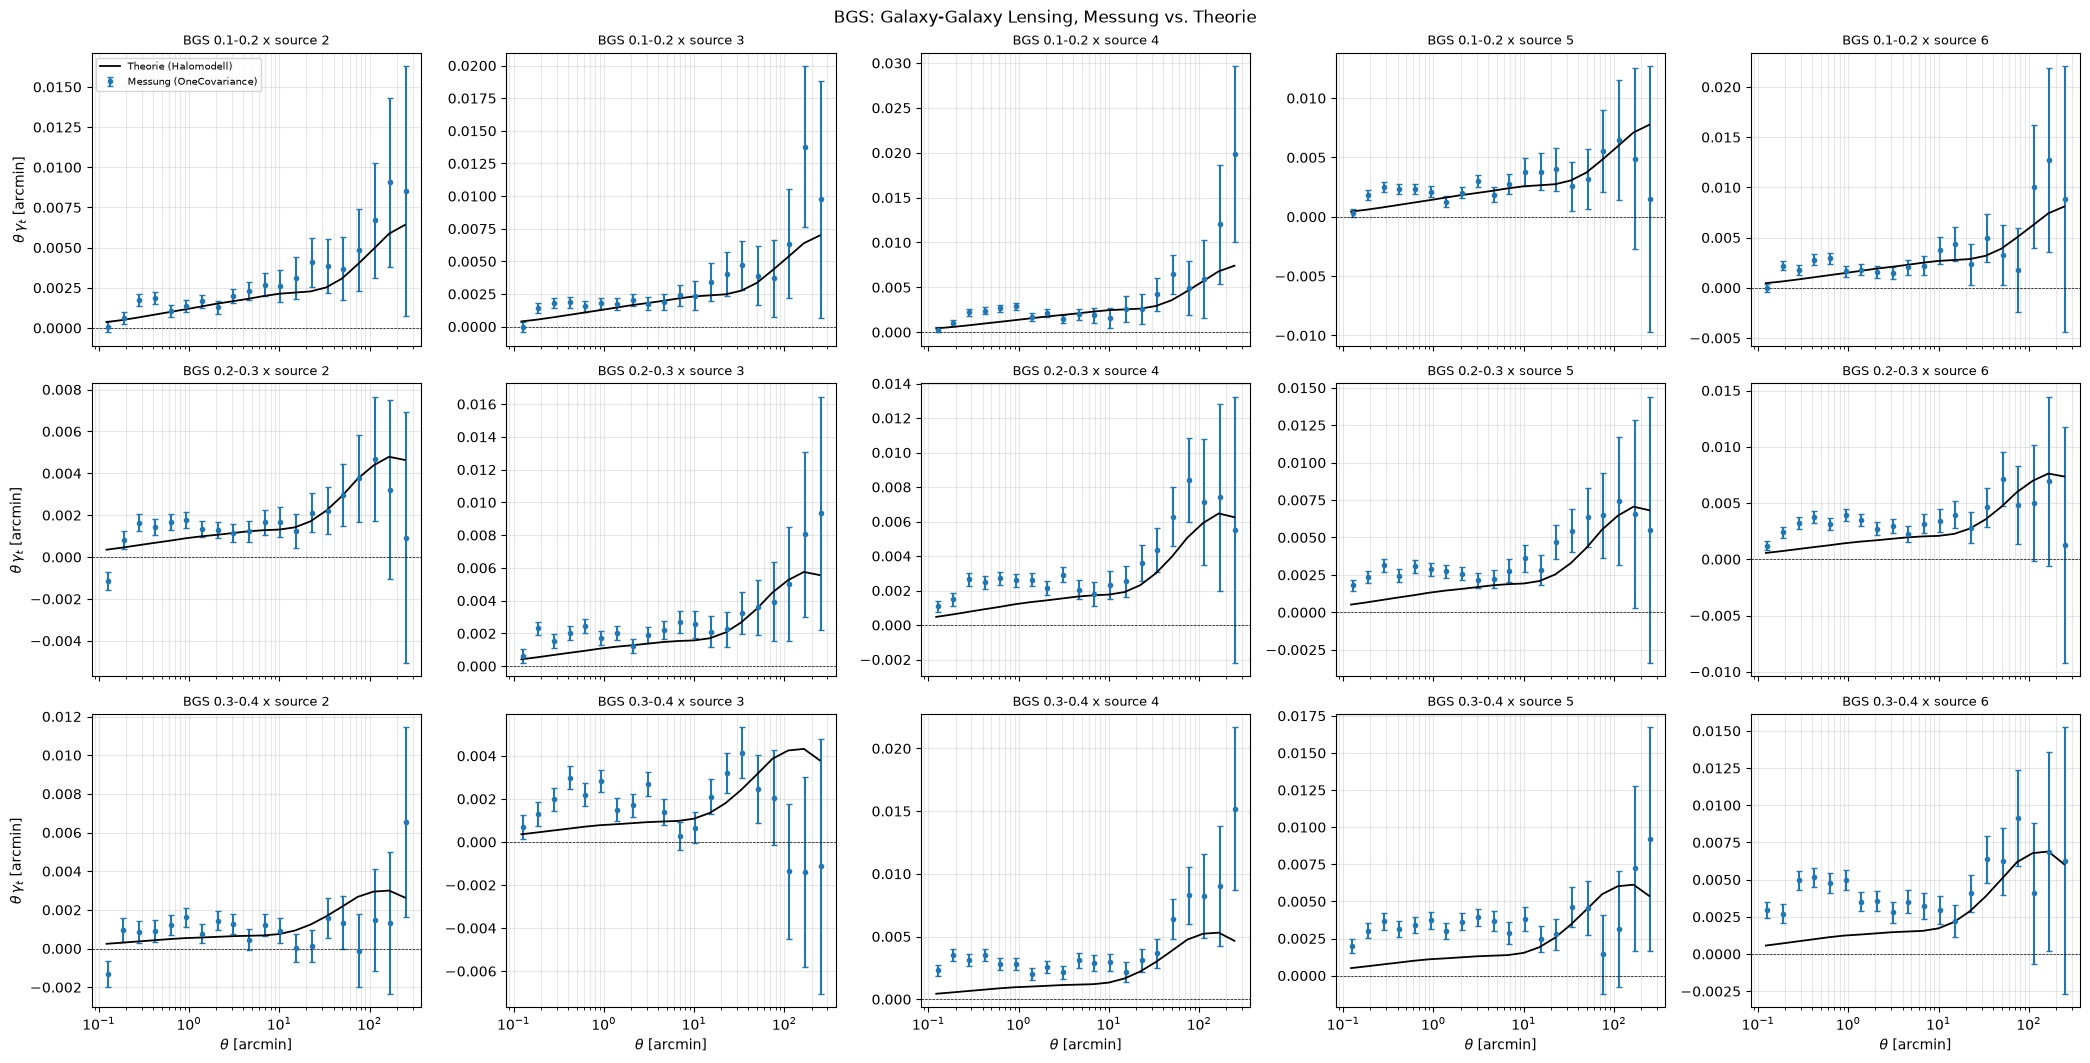

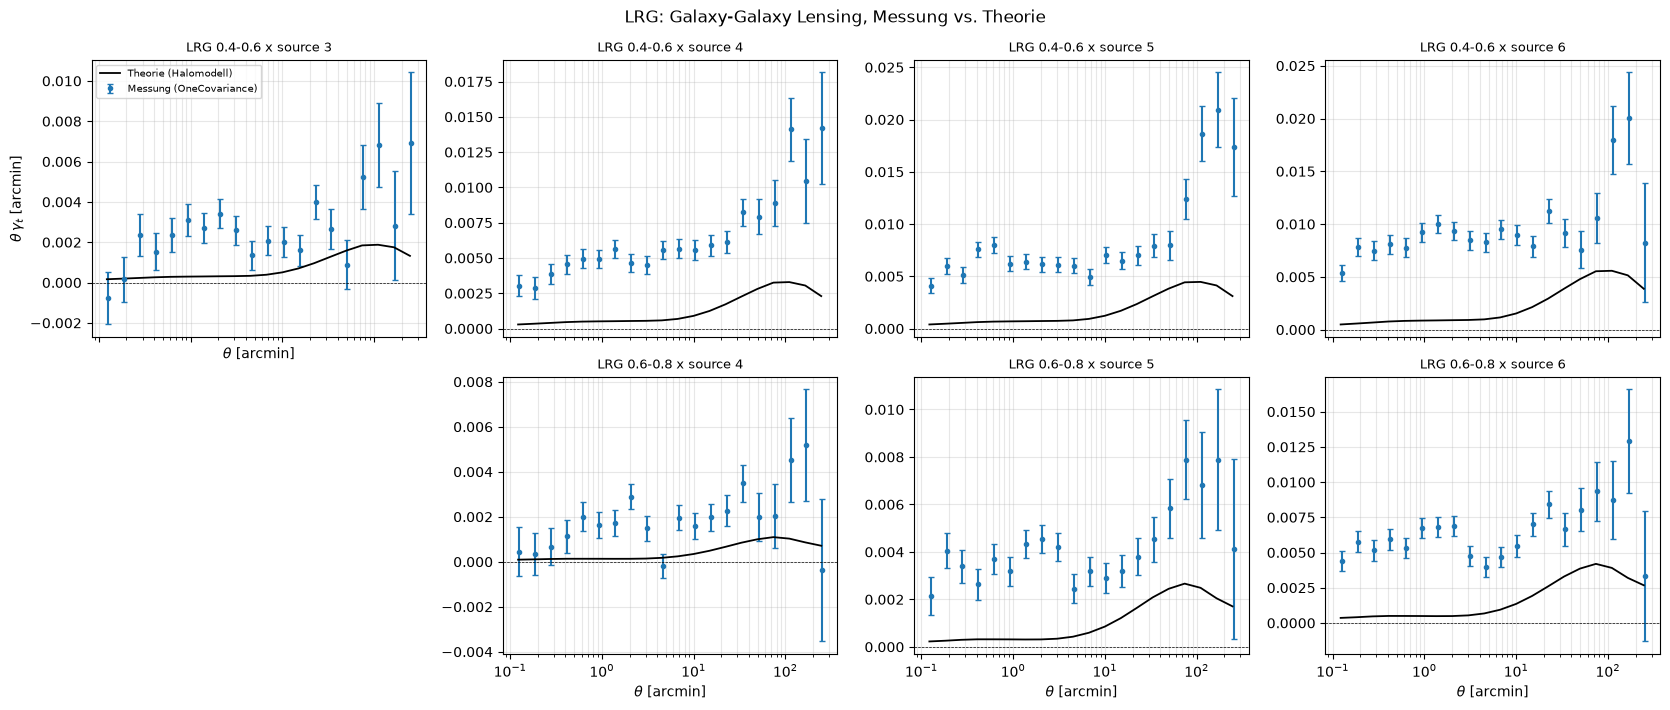

In [8]:
source_bin_labels = {
    1: r'TOMOBIN 1 ($0.11 < z_B < 0.42$)',
    2: r'TOMOBIN 2 ($0.43 < z_B < 0.58$)',
    3: r'TOMOBIN 3 ($0.59 < z_B < 0.71$)',
    4: r'TOMOBIN 4 ($0.72 < z_B < 0.90$)',
    5: r'TOMOBIN 5 ($0.91 < z_B < 1.14$)',
    6: r'TOMOBIN 6 ($1.15 < z_B < 2.00$)',
}

pair_set = set(pairs)
samples = {}
for lens in lens_names:
    samples.setdefault(lens.split('_')[0], []).append(lens)

for sample, sample_lenses in samples.items():
    src_bins = sorted({sb for ln, sb in pairs if ln in sample_lenses})

    fig, axes = plt.subplots(
        len(sample_lenses), len(src_bins),
        figsize=(4.2 * len(src_bins), 3.6 * len(sample_lenses)),
        squeeze=False, sharex=True,
    )
    for a, ln in enumerate(sample_lenses):
        for b, sb in enumerate(src_bins):
            ax = axes[a, b]
            if (ln, sb) not in pair_set:
                ax.axis('off')
                continue
            key = f'{ln}_S{sb}'
            r = meas[f'theta_{key}']
            ax.errorbar(
                r, r * meas[f'gammat_{key}'], yerr=r * meas[f'sigma_onecov_{key}'],
                fmt='o', ms=3, capsize=2, color='tab:blue',
                label='Messung (OneCovariance)',
            )
            ax.plot(theta_theory, theo[f'theta_gamma_t_{key}'],
                    color='k', lw=1.3, label='Theorie (Halomodell)')
            ax.axhline(0, color='k', lw=0.5, ls='--')
            ax.set_xscale('log')
            ax.set_title(f'{ln.replace("_", " ")} x source {sb}', fontsize=9)
            if b == 0:
                ax.set_ylabel(r'$\theta\,\gamma_t$ [arcmin]')
            if a == len(sample_lenses) - 1 or not any(
                (sample_lenses[i], sb) in pair_set for i in range(a + 1, len(sample_lenses))
            ):
                ax.set_xlabel(r'$\theta$ [arcmin]')
            ax.grid(True, which='both', alpha=0.3)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f'{sample}: Galaxy-Galaxy Lensing, Messung vs. Theorie')
    fig.tight_layout()
    plt.show()